Value(data=6, gradient=1)


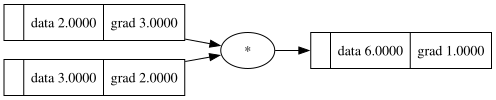

In [99]:
import importlib
import micrograd.value
import micrograd.nn

importlib.reload(micrograd.value)
importlib.reload(micrograd.nn)

from micrograd.value import Value
from micrograd.nn import MLP
from visualization.visualize import draw_dot

a = Value(2)
b = Value(3)
c = a * b

c.backward()

print(c)
draw_dot(c)

In [100]:
import random
import numpy as np

SEED = 1337
random.seed(SEED)
np.random.seed(SEED)

In [101]:
# Create the model
input_dimensionality = 2
hidden_layers = [16,16,1]
model = MLP(input_dimensionality, hidden_layers)

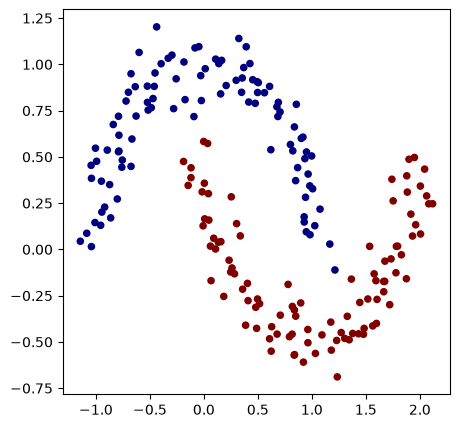

In [106]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples=200, noise=0.1)

# y = y*2 - 1 # make y be -1 or 1
# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [ ]:
# Convert dataset to Values
train_split = 0.8
split = int(len(X) * 0.8)
x_train = X[:split]
x_validation = X[split:]

y_train = y[: split]
y_validation = y[split :]

# Train
x_train = [list(map(Value, x_row)) for x_row in x_train]
y_train = list(map(Value, y_train))

# Validation
x_validation = [list(map(Value, x_row)) for x_row in x_validation]
y_validation = list(map(Value, y_validation))


In [108]:
# Given the predicted and true values we will return the binary cross_entropy_loss
def binary_cross_entropy_loss(predicted_values: list[Value], true_values: list[Value]) -> tuple[Value, float]:
    num_predictions = len(predicted_values)
    sum_of_distances = Value(0)

    for (predicted, actual) in zip(predicted_values, true_values):
        probability = predicted.sigmoid()
        sum_of_distances += actual * probability.log() + (1 - actual) * (1 - probability).log()

    normalized = - sum_of_distances / num_predictions

    accuracy = sum(((actual.data == 1) == (predicted.data >= 0) for predicted, actual in zip(predicted_values, true_values)))
    accuracy /= len(predicted_values)

    return (normalized, accuracy)

In [ ]:
# Optimization loop
STEPS = 200


# Could add decay or warmup period

for i in range(STEPS):

    # Forward pass. The model cannot deal with multiple rows
    # List comprehension to run
    model_output = [model(x)[0] for x in x_train]
    
    # This is the training loss. We should compute the val loss too
    total_loss, accuracy = binary_cross_entropy_loss(model_output, y_train)

    # zero the accumulated gradients
    model.zero_grad()
    total_loss.backward()

    # optimization step using sgd
    learning_rate = 1.0 - 0.9 * i / STEPS
    for parameter in model.parameters():
        parameter.data -= parameter.gradient * learning_rate

    print(f"step {i} loss {total_loss.data}, accuracy {accuracy * 100}%")

    if i % 20 == 0:
        model_validation_output = [model(x)[0] for x in x_validation]
        validation_loss, val_accuracy = binary_cross_entropy_loss(model_validation_output, y_validation)

        print(f"VALIDATION step {i} loss {validation_loss.data}, accuracy {val_accuracy * 100}%")


step 0 loss 0.2607378186964203, accuracy 86.25%
VALIDATION step 0 loss 0.40906235871145524, accuracy 77.5%
step 1 loss 0.24777733726200102, accuracy 88.75%
step 2 loss 0.23766604112535356, accuracy 90.0%
step 3 loss 0.22805518439742142, accuracy 91.25%
step 4 loss 0.22035424379976976, accuracy 91.25%
step 5 loss 0.21434962427740936, accuracy 91.875%
step 6 loss 0.20898880161335098, accuracy 92.5%
step 7 loss 0.20423756212963748, accuracy 92.5%
step 8 loss 0.20012100738183644, accuracy 92.5%
step 9 loss 0.1964724649929536, accuracy 92.5%
step 10 loss 0.19314633121296954, accuracy 92.5%
step 11 loss 0.19001379896754553, accuracy 92.5%
step 12 loss 0.18672571601626728, accuracy 93.125%
step 13 loss 0.1836647407037067, accuracy 93.75%
step 14 loss 0.1804695841013898, accuracy 93.75%
step 15 loss 0.17721915849508668, accuracy 93.75%
step 16 loss 0.17428162176083498, accuracy 93.75%
step 17 loss 0.17127076088868587, accuracy 94.375%
step 18 loss 0.16842490551434489, accuracy 94.375%
step 19 

(-1.6889782086876892, 2.061021791312311)

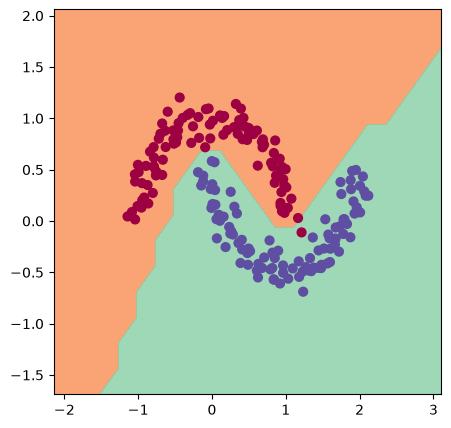

In [110]:
# Draw decision boundary
step = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, step), np.arange(y_min, y_max, step))

grid = np.c_[xx.ravel(), yy.ravel()]
scores = [model([Value(x0), Value(x1)])[0] for x0, x1 in grid]
predictions = np.array([score.data >= 0 for score in scores]).reshape(xx.shape)

plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, predictions, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())